In [80]:
import hashlib
import logging
import random
import warnings
from collections import OrderedDict
from copy import deepcopy
from inspect import Parameter
from typing import Iterable

import cirq
import numpy as np
from matplotlib import pyplot as plt
import pennylane as qp
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from mitiq import Executor
from mitiq.pec import (
    NoisyOperation,
    OperationRepresentation,
    combine_results,
    construct_circuits,
    execute_with_pec
)
from mitiq.pec.representations import represent_operation_with_local_depolarizing_noise
from mitiq.zne.inference import LinearFactory
from mitiq.zne.scaling import fold_global

from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import EfficientSU2, ZFeatureMap
from qiskit.primitives import BaseEstimatorV2, BackendEstimatorV2
from qiskit.primitives import BackendEstimatorV2 as LocalEstimatorV2
from qiskit.primitives.containers import PrimitiveResult, PubResult
from qiskit.primitives.containers.estimator_pub import EstimatorPub
from qiskit.providers import JobStatus
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit_aer.primitives import EstimatorV2 as Estimator

from qiskit_algorithms.gradients import ParamShiftEstimatorGradient, ReverseEstimatorGradient
from qiskit_machine_learning.connectors import TorchConnector
from qiskit_machine_learning.neural_networks import EstimatorQNN

from qiskit_ibm_runtime import Batch, EstimatorV2, QiskitRuntimeService, Session
from qiskit_ibm_runtime import EstimatorV2 as RuntimeEstimatorV2
from qiskit_ibm_runtime.options import EstimatorOptions

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

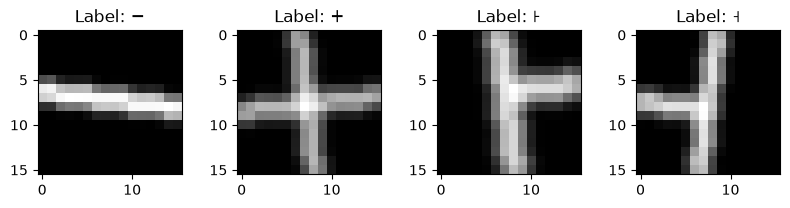

In [81]:
#loading dataset
[pm] = qp.data.load('other', name='plus-minus')

X_train = pm.img_train  # shape (1000,16,16)
X_test = pm.img_test  # shape (200,16,16)
Y_train = pm.labels_train  # shape (1000,)
Y_test = pm.labels_test  # shape (200,)

x_vis = [
    (X_train[Y_train == 0])[0],
    (X_train[Y_train == 1])[0],
    (X_train[Y_train == 2])[0],
    (X_train[Y_train == 3])[0],
]
y_vis = [0, 1, 2, 3]

#visualizing each class
def visualize_data(x, y, pred=None):
    n_img = len(x)
    labels_list = ["\u2212", "\u002b", "\ua714", "\u02e7"]
    fig, axes = plt.subplots(1, 4, figsize=(8, 2))
    for i in range(n_img):
        axes[i].imshow(x[i], cmap="gray")
        if pred is None:
            axes[i].set_title("Label: {}".format(labels_list[y[i]]))
        else:
            axes[i].set_title("Label: {}, Pred: {}".format(labels_list[y[i]], labels_list[pred[i]]))
    plt.tight_layout(w_pad=2)
    plt.show()

visualize_data(x_vis, y_vis)

In [82]:
#prepare the noisy backend for the noisy simulator
service = QiskitRuntimeService()

real_backend = service.backend("ibm_aachen")

aer_backend = AerSimulator.from_backend(real_backend)
aer_backend.set_options(seed_simulator=42)
estimator = AerEstimator()
estimator.options.simulator = {
    "noise_model": aer_backend.options.noise_model,
    "method": "density_matrix",
}


In [83]:
#noisy backend estimation ibm_aachen noise
class QiskitReuploadingClassifier(nn.Module):
    def __init__(self,input_dim=256,output_dim=4,num_qubits=8,num_layers=2,estimator=None,backend=None):
        super().__init__()
        self.num_qubits=num_qubits
        self.output_dim=output_dim
        self.num_layers=num_layers
        self.total_angles=num_layers*num_qubits*3
        self.input_projection=nn.Linear(input_dim,self.total_angles)
        self.weights=nn.Parameter(0.1*torch.rand(self.total_angles))
        self.bias=nn.Parameter(0.1*torch.rand(self.total_angles))

        self.logical_qc,self.params=self._build_strongly_entangling_circuit()

        self.logical_observables=[
            SparsePauliOp.from_sparse_list([("Z",[i],1)],num_qubits=self.num_qubits)
            for i in range(self.output_dim)
        ]

        self.qc=self.logical_qc.copy()

        if backend is not None:
            self.qc=transpile(self.qc,target=backend.target,optimization_level=0,seed_transpiler=42)

        self.observables=[
            obs.apply_layout(self.qc.layout) if self.qc.layout is not None else obs
            for obs in self.logical_observables
        ]

        qnn=EstimatorQNN(
            circuit=self.qc,
            observables=self.observables,
            input_params=self.params,
            weight_params=[],
            estimator=estimator,
            input_gradients=True,
            gradient=ParamShiftEstimatorGradient(estimator=estimator)
        )

        self.qcircuit=TorchConnector(qnn)

    def _build_strongly_entangling_circuit(self):
        qc=QuantumCircuit(self.num_qubits)
        params=ParameterVector("θ",self.total_angles)
        idx=0
        for layer in range(self.num_layers):
            for q in range(self.num_qubits):
                qc.rz(params[idx],q)
                qc.ry(params[idx+1],q)
                qc.rz(params[idx+2],q)
                idx+=3
            step=(layer%(self.num_qubits-1))+1
            for q in range(self.num_qubits):
                target=(q+step)%self.num_qubits
                qc.cx(q,target)
        return qc,params

    def forward(self,x):
        angles=self.input_projection(x)
        angles=self.weights*angles+self.bias
        return self.qcircuit(angles)
    

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = QiskitReuploadingClassifier(
    estimator=estimator,
).to(device)

dummy_data = torch.rand(5, 256).to(device) 
output = model(dummy_data)

print("Output shape:", output.shape) # Expected: [5, 4]

Using device: cpu
Output shape: torch.Size([5, 4])


In [84]:
# Hyperparameters 
learning_rate = 0.05
epochs = 3
batch_size = 20
input_dim = 256
num_classes = 4
num_qubits = 8
num_layers = 2

feats_train = torch.from_numpy(X_train[:200]).reshape(200, -1).float().to(device)
feats_test = torch.from_numpy(X_test[:50]).reshape(50, -1).float().to(device)
labels_train = torch.from_numpy(Y_train[:200]).long().to(device)
labels_test = torch.from_numpy(Y_test[:50]).long().to(device)
num_train = feats_train.shape[0]

qml_model = QiskitReuploadingClassifier(
    input_dim=input_dim, 
    output_dim=num_classes, 
    num_qubits=num_qubits, 
    num_layers=num_layers,
    estimator=estimator,
    backend=aer_backend,
).to(device)

loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(qml_model.parameters(), lr=learning_rate)
num_batches = num_train // batch_size

def accuracy(labels, predictions):
    predicted_classes = torch.argmax(predictions, dim=1)
    correct = (predicted_classes == labels).sum().item()
    return correct / len(labels)

def gen_batches(num_samples, num_batches):
    assert num_samples % num_batches == 0
    perm_ind = torch.reshape(torch.randperm(num_samples), (num_batches, -1))
    return perm_ind


def print_acc(epoch, max_ep=4):
    with torch.no_grad():
        predictions_train = qml_model(feats_train[:50])
        predictions_test = qml_model(feats_test)
        
        cost_approx_train = loss(predictions_train, labels_train[:50])
        cost_approx_test = loss(predictions_test, labels_test)
        
        acc_approx_train = accuracy(labels_train[:50], predictions_train)
        acc_approx_test = accuracy(labels_test, predictions_test)
        
    print(
        f"Epoch {epoch}/{max_ep} | Approx Cost (train): {cost_approx_train:0.7f} | Cost (val): {cost_approx_test:0.7f} |"
        f" Approx Acc train: {acc_approx_train:0.7f} | Acc val: {acc_approx_test:0.7f}"
    )


Starting training loop for Qiskit variational classifier (8 qubits, 2 layers)...
Epoch 0/3 | Approx Cost (train): 1.3816185 | Cost (val): 1.3866271 | Approx Acc train: 0.3000000 | Acc val: 0.2000000
Epoch 1/3 | Approx Cost (train): 0.9562461 | Cost (val): 0.9199833 | Approx Acc train: 0.8400000 | Acc val: 0.8800000
Epoch 2/3 | Approx Cost (train): 0.7653684 | Cost (val): 0.7815375 | Approx Acc train: 1.0000000 | Acc val: 1.0000000
Epoch 3/3 | Approx Cost (train): 0.6935887 | Cost (val): 0.6675767 | Approx Acc train: 0.9800000 | Acc val: 1.0000000


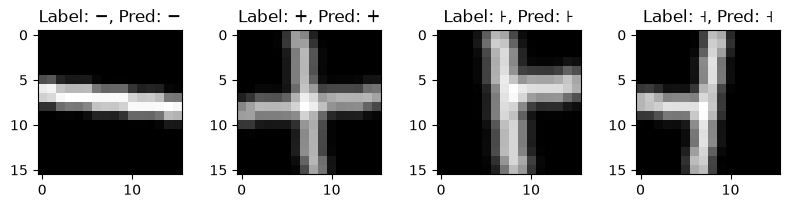

In [85]:
print(f"Starting training loop for Qiskit variational classifier ({num_qubits} qubits, {num_layers} layers)...")

for ep in range(epochs):
    batch_ind = gen_batches(num_train, num_batches)
    print_acc(epoch=ep, max_ep=epochs)

    for it in range(num_batches):
        optimizer.zero_grad()
        
        feats_train_batch = feats_train[batch_ind[it]]
        labels_train_batch = labels_train[batch_ind[it]]
        outputs = qml_model(feats_train_batch)
        batch_loss = loss(outputs, labels_train_batch)
        batch_loss.backward()
        optimizer.step()

print_acc(epochs, max_ep=epochs)

x_vis_torch = torch.from_numpy(np.array(x_vis).reshape(4, -1)).float().to(device)
y_vis_torch = torch.from_numpy(np.array(y_vis)).long().to(device)

with torch.no_grad():
    benign_preds = qml_model(x_vis_torch)

benign_class_output = torch.argmax(benign_preds, dim=1).cpu().numpy()
visualize_data(x_vis, y_vis, benign_class_output)

In [88]:
save_path = "qiskit_reuploading_classifier_with_noise_psr.pth"
torch.save({
    "model_state_dict": qml_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": epochs,
    "learning_rate": learning_rate,
}, save_path)
print(f"Model weights saved to {save_path}")

Model weights saved to qiskit_reuploading_classifier_with_noise_psr.pth


In [119]:
#training skipped
checkpoint = torch.load("qiskit_reuploading_classifier_with_noise_psr.pth", map_location=device)

qml_model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
start_epoch = checkpoint["epoch"]

feats_train = torch.from_numpy(X_train[:200]).reshape(200, -1).float().to(device)
feats_test = torch.from_numpy(X_test[:50]).reshape(50, -1).float().to(device)
labels_train = torch.from_numpy(Y_train[:200]).long().to(device)
labels_test = torch.from_numpy(Y_test[:50]).long().to(device)

x_vis_torch = torch.from_numpy(np.array(x_vis).reshape(4, -1)).float().to(device)
y_vis_torch = torch.from_numpy(np.array(y_vis)).long().to(device)

In [120]:
qml_model.eval() 

with torch.no_grad():
    adversarial_preds_before = qml_model(feats_test)

adversarial_class_output_before = torch.argmax(adversarial_preds_before, dim=1)
acc = accuracy(labels_test, adversarial_preds_before)
print(f"Accuracy before PGD Attack: {acc:0.4f}")

Accuracy before PGD Attack: 1.0000


In [121]:
#PGD attack
loss_fn = nn.CrossEntropyLoss()

def PGD(model, feats, labels, epsilon=0.05, alpha=0.01, num_iter=5):
    model.eval()

    delta = torch.zeros_like(feats, requires_grad=True)

    for _ in range(num_iter):
        model.zero_grad()

        outputs = model(feats + delta)
        loss = loss_fn(outputs, labels)
        loss.backward()

        with torch.no_grad():
            delta += alpha * delta.grad.sign()
            delta.clamp_(-epsilon, epsilon)

        delta.grad.zero_()

    return delta.detach()

In [ ]:
# checkpoint = torch.load( "qiskit_reuploading_classifier_with_noise_psr.pth", map_location=device, ) 
# qml_model.load_state_dict(checkpoint["model_state_dict"]) 
# service = QiskitRuntimeService() 
# hardware_estimator = MitiqZNEEstimatorV2( backend=aer_backend, 
#                                           noise_factors=[1.0, 3.0, 5.0], ) 


# hardware_model = QiskitReuploadingClassifier( input_dim=input_dim, 
#                                              output_dim=num_classes, 
#                                              num_qubits=num_qubits, 
#                                              num_layers=num_layers, 
#                                              estimator=hardware_estimator, 
#                                              backend=aer_backend, )

# hardware_model.load_state_dict(checkpoint["model_state_dict"]) 
# hardware_model.eval()

# loss_fn = nn.CrossEntropyLoss()
# def PGD_ZNE(model, feats, labels, epsilon=0.05, alpha=0.01, num_iter=10):
#     hardware_model.eval()

#     delta = torch.zeros_like(feats)

#     for _ in range(num_iter):
#         delta.requires_grad_(True)

#         outputs = model(feats + delta)
#         loss = loss_fn(outputs, labels)

#         grad = torch.autograd.grad(loss,delta,retain_graph=False,create_graph=False,)[0]

#         with torch.no_grad():
#             delta += alpha * grad.sign()
#             delta.clamp_(-epsilon, epsilon)

#         delta = delta.detach()

#     return delta

# hardware_model.eval()

# delta = PGD_ZNE(hardware_model,feats_test,labels_test,epsilon=0.05,alpha=0.01,num_iter=10,)

# adv_test_features = (feats_test + delta).detach()

# with torch.no_grad():
#     adv_predictions = hardware_model(adv_test_features)

# adv_acc = accuracy(labels_test,adv_predictions,)

# print(
#     f"ZNE model accuracy on PGD adversarial samples: "
#     f"{adv_acc:.4f}"
# )

OrderedDict([('rz', 106), ('sx', 86), ('cz', 28), ('x', 1)])
['cz', 'rz', 'sx', 'x']
120
48

Creating cached ZNE templates...
  Folding scale 1.0
    qubits: 120
    parameters: 48
    depth: 62
  Folding scale 3.0
    qubits: 120
    parameters: 48
    depth: 207
  Folding scale 5.0
    qubits: 120
    parameters: 48
    depth: 352

Creating cached ZNE templates...
  Folding scale 1.0
    qubits: 120
    parameters: 48
    depth: 62
  Folding scale 3.0
    qubits: 120
    parameters: 48
    depth: 207
  Folding scale 5.0
    qubits: 120
    parameters: 48
    depth: 352


In [92]:
# epsilon = 0.01
# while epsilon <= 0.1:
#     perturbations_test = PGD(model=qml_model, feats=feats_test, labels=labels_test, epsilon=epsilon)
#     perturbed_feats_test = feats_test + perturbations_test
#     print(perturbations_test.abs().max())
#     print(perturbations_test.abs().mean())
#     qml_model.eval()
#     #tensor(0.0500)
#     #tensor(0.0448)

#     with torch.no_grad():
#         adversarial_preds_after = qml_model(perturbed_feats_test)

#     adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
#     adv_acc = accuracy(labels_test, adversarial_preds_after)
#     print(epsilon)
#     print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")
#     epsilon += 0.005
#     qml_model.train()



In [128]:
perturbations_test = PGD(model=qml_model, feats=feats_test, labels=labels_test, epsilon=0.05)
perturbed_feats_test = feats_test + perturbations_test
print(perturbations_test.abs().max())
print(perturbations_test.abs().mean())
qml_model.eval()
#tensor(0.0500)
#tensor(0.0448)

with torch.no_grad():
    adversarial_preds_after = qml_model(perturbed_feats_test)

adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")
qml_model.train()


tensor(0.0500)
tensor(0.0450)
Accuracy AFTER PGD Attack: 0.5000


QiskitReuploadingClassifier(
  (input_projection): Linear(in_features=256, out_features=48, bias=True)
  (qcircuit): TorchConnector()
)


After PGD Atack Vis_data:


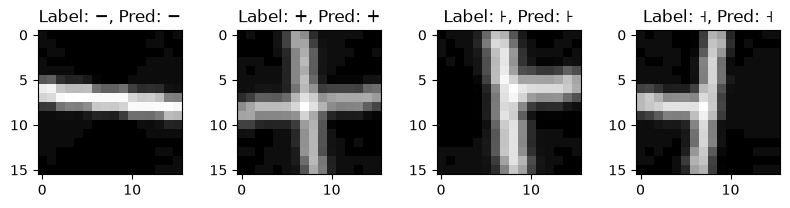

In [ ]:
# perturbations = PGD(model=qml_model, feats=x_vis_torch, labels=y_vis_torch, epsilon=0.025)
# perturbed_x = x_vis_torch + perturbations
# qml_model.eval()
# adversarial_preds_after = qml_model(perturbed_x)
# adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)

# print("\nAfter PGD Atack Vis_data:")
# visualize_data(perturbed_x.cpu().detach().numpy().reshape(-1, 16, 16), y_vis, adversarial_class_output_after.cpu().numpy())

In [11]:
torch.save({
    'feats_test': feats_test,
    'labels_test': labels_test,
    'perturbations_test': perturbations_test,
    'perturbed_feats_test': perturbed_feats_test
}, 'pgd_attack_data.pt')

In [124]:
saved_data = torch.load('pgd_attack_data.pt')

feats_test = saved_data['feats_test']
labels_test = saved_data['labels_test']
perturbations_test = saved_data['perturbations_test']
perturbed_feats_test = saved_data['perturbed_feats_test']

In [129]:
qml_model.eval()
adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")
qml_model.train()


Accuracy AFTER PGD Attack: 0.5000


QiskitReuploadingClassifier(
  (input_projection): Linear(in_features=256, out_features=48, bias=True)
  (qcircuit): TorchConnector()
)

In [110]:
adv_dataset = (
    PGD(model=qml_model, feats=feats_train[:50], labels=labels_train[:50], epsilon=0.05)
    + feats_train[:50]
)

feats_retrain = torch.cat((feats_train, adv_dataset))
labels_retrain = torch.cat((labels_train, labels_train[:50]))
epochs_retraining = 3

for ep in range(0, epochs_retraining):
    batch_ind = gen_batches(num_train, num_batches)
    print_acc(epoch=ep, max_ep=3)

    for it in range(num_batches):
        optimizer.zero_grad()
        feats_train_batch = feats_retrain[batch_ind[it]]
        labels_train_batch = labels_retrain[batch_ind[it]]

        outputs = qml_model(feats_train_batch)
        batch_loss = loss(outputs, labels_train_batch)
        # if REG:
        #    loss = loss + lipschitz_regularizer(regularization_rate, model.qcircuit.weights)
        batch_loss.backward()
        optimizer.step()

print_acc(epochs_retraining, max_ep=3)


Epoch 0/3 | Approx Cost (train): 0.6692340 | Cost (val): 0.6332060 | Approx Acc train: 1.0000000 | Acc val: 1.0000000
Epoch 1/3 | Approx Cost (train): 0.5470127 | Cost (val): 0.5006939 | Approx Acc train: 1.0000000 | Acc val: 1.0000000
Epoch 2/3 | Approx Cost (train): 0.5301853 | Cost (val): 0.5014694 | Approx Acc train: 1.0000000 | Acc val: 1.0000000
Epoch 3/3 | Approx Cost (train): 0.5081001 | Cost (val): 0.4882045 | Approx Acc train: 1.0000000 | Acc val: 1.0000000


In [112]:
save_path = "qiskit_reuploading_classifier_after_attack_with_noise_psr.pth"
torch.save({
    "model_state_dict": qml_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": epochs,
    "learning_rate": learning_rate,
}, save_path)
print(f"Model weights saved to {save_path}")

Model weights saved to qiskit_reuploading_classifier_after_attack_with_noise_psr.pth


In [98]:
checkpoint = torch.load("qiskit_reuploading_classifier_after_attack_with_noise_psr.pth", map_location=device)

qml_model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
start_epoch = checkpoint["epoch"]
learning_rate=checkpoint["learning_rate"]

In [111]:
qml_model.eval()

with torch.no_grad():
    adversarial_preds_after = qml_model(perturbed_feats_test)

adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")

Accuracy AFTER PGD Attack: 0.7600


In [113]:
perturbations_test = PGD(model=qml_model, feats=feats_test, labels=labels_test, epsilon=0.05)
perturbed_feats_test = feats_test + perturbations_test
print(perturbations_test.abs().max())
print(perturbations_test.abs().mean())
qml_model.eval()
#tensor(0.0500)
#tensor(0.0448)

with torch.no_grad():
    adversarial_preds_after = qml_model(perturbed_feats_test)

adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")
qml_model.train()


tensor(0.0500)
tensor(0.0473)
Accuracy AFTER PGD Attack: 0.7000


QiskitReuploadingClassifier(
  (input_projection): Linear(in_features=256, out_features=48, bias=True)
  (qcircuit): TorchConnector()
)

In [114]:
class _SynchronousJob:
    def __init__(self, result_data):
        self._result_data = result_data

    def result(self):
        return self._result_data
    
    def status(self):
        return JobStatus.DONE

class MitiqZNEEstimatorV2(BaseEstimatorV2):

    def __init__(self, backend, noise_factors=(1.0, 3.0, 5.0), max_pubs_per_run=12):
        super().__init__()
        self.backend = backend
        self.base_estimator = BackendEstimatorV2(backend=backend)
        self.noise_factors = tuple(float(x) for x in noise_factors)

        if len(self.noise_factors) == 0:
            raise ValueError("noise_factors cannot be empty.")

        for scale in self.noise_factors:
            if not float(scale).is_integer():
                raise ValueError("This implementation requires integer noise factors. Use e.g. (1, 3, 5).")
            scale = int(scale)
            if scale < 1 or scale % 2 == 0:
                raise ValueError("Noise factors must be positive odd integers, e.g. (1, 3, 5).")

        self.max_pubs_per_run = int(max_pubs_per_run)

        if self.max_pubs_per_run < len(self.noise_factors):
            raise ValueError("max_pubs_per_run must be >= len(noise_factors).")

        self._folded_cache = {}
        self.zne_coefficients = self._compute_zne_coefficients(self.noise_factors)

    def run(self, pubs, *, precision=None, **run_options):
        result = self._run_mitiq(pubs, precision=precision, **run_options)
        return _SynchronousJob(result)

    @staticmethod
    def _compute_zne_coefficients(noise_factors):
        """
        Compute coefficients c_i such that
            E_ZNE = sum_i c_i E(noise_factor_i)
        corresponds to Lagrange extrapolation at zero noise.
        """
        x = np.asarray(noise_factors, dtype=np.float64)
        coefficients = np.ones(len(x), dtype=np.float64)

        for i in range(len(x)):
            for j in range(len(x)):
                if i == j:
                    continue
                coefficients[i] *= (-x[j] / (x[i] - x[j]))

        return coefficients

    @staticmethod
    def _make_parameter_dict(bindings, row):
        param_dict = {}
        for keys, values in bindings.data.items():
            row_values = values[row] if bindings.shape else values
            if isinstance(keys, tuple):
                for key, value in zip(keys, row_values):
                    param_dict[key] = value
            else:
                param_dict[keys] = row_values
        return param_dict

    @staticmethod
    def _bind_parameter_dict(circuit, param_dict):
        return circuit.assign_parameters(param_dict, strict=False)

    @staticmethod
    def _cache_key(circuit):
        instructions = []
        for instruction in circuit.data:
            op = instruction.operation
            qargs = tuple(circuit.find_bit(q).index for q in instruction.qubits)
            cargs = tuple(circuit.find_bit(c).index for c in instruction.clbits)
            params = tuple(str(parameter) for parameter in op.params)
            instructions.append((op.name, qargs, cargs, params))
        return (circuit.num_qubits, circuit.num_clbits, str(circuit.global_phase), tuple(instructions))

    def clear_cache(self):
        self._folded_cache.clear()

    @staticmethod
    def _inverse_circuit(circuit):
        """Construct U† while preserving Qiskit ParameterExpressions."""
        inverse = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
        inverse.global_phase = -circuit.global_phase

        for instruction in reversed(circuit.data):
            op = instruction.operation
            qargs = instruction.qubits
            cargs = instruction.clbits
            if op.name in {"measure", "reset", "barrier"}:
                continue
            inverse.append(op.inverse(), qargs, cargs)

        return inverse

    @classmethod
    def _fold_global_qiskit(cls, circuit, scale_factor):
        """
        Parameter-preserving global folding.
        scale 1: U
        scale 3: U U† U
        scale 5: U U† U U† U
        """
        scale = int(round(float(scale_factor)))

        if scale < 1 or scale % 2 == 0:
            raise ValueError("Global folding requires positive odd integer scale factors.")

        if scale == 1:
            return circuit.copy()

        base = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
        base.global_phase = circuit.global_phase

        for instruction in circuit.data:
            op = instruction.operation
            qargs = instruction.qubits
            cargs = instruction.clbits
            if op.name == "barrier":
                continue
            if op.name in {"measure", "reset"}:
                raise ValueError(f"Global folding requires a unitary circuit. Found {op.name}.")
            base.append(op, qargs, cargs)

        inverse = cls._inverse_circuit(base)
        folded = QuantumCircuit(base.num_qubits, base.num_clbits)
        folded.global_phase = base.global_phase
        repetitions = (scale - 1) // 2
        folded.compose(base, inplace=True)

        for _ in range(repetitions):
            folded.compose(inverse, inplace=True)
            folded.compose(base, inplace=True)

        return folded

    @staticmethod
    def _replace_sxdg(circuit):
        new_circuit = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
        new_circuit.global_phase = circuit.global_phase
        new_circuit.metadata = circuit.metadata

        for instruction in circuit.data:
            op = instruction.operation
            qargs = instruction.qubits
            cargs = instruction.clbits

            if op.name == "sxdg":
                q = qargs[0]
                new_circuit.sx(q)
                new_circuit.x(q)
            else:
                new_circuit.append(op, qargs, cargs)

        return new_circuit
    
    def _get_folded_templates(self, circuit):
        key = self._cache_key(circuit)
        cached = self._folded_cache.get(key)
        if cached is not None:
            return cached

        print("\nCreating cached ZNE templates...")
        folded_templates = {}

        for scale in self.noise_factors:
            print(f"  Folding scale {scale}")
            folded = self._fold_global_qiskit(circuit, scale)
            folded = self._replace_sxdg(folded)
            folded_templates[scale] = folded
            print(f"    qubits: {folded.num_qubits}")
            print(f"    parameters: {folded.num_parameters}")
            print(f"    depth: {folded.depth()}")

        self._folded_cache[key] = folded_templates
        return folded_templates

    def _execute_chunk(self, pubs, precision, run_options):
        if not pubs:
            return []
        job = self.base_estimator.run(pubs, precision=precision, **run_options)
        result = job.result()
        return [result[i] for i in range(len(result))]

    def _run_mitiq(self, pubs, precision=None, **run_options):
        coerced_pubs = [EstimatorPub.coerce(pub) for pub in pubs]
        batch_sizes = []
        all_base_results = []
        chunk_pubs = []
        num_factors = len(self.noise_factors)
        chunk_size = self.max_pubs_per_run

        for pub in coerced_pubs:
            circuit = pub.circuit
            observables = pub.observables
            bindings = pub.parameter_values
            batch_size = bindings.shape[0] if bindings.shape else 1
            batch_sizes.append(batch_size)
            folded_templates = self._get_folded_templates(circuit)

            for row in range(batch_size):
                param_dict = self._make_parameter_dict(bindings, row)
                for scale in self.noise_factors:
                    template = folded_templates[scale]
                    bound_circuit = self._bind_parameter_dict(template, param_dict)
                    chunk_pubs.append((bound_circuit, observables))

                if len(chunk_pubs) >= chunk_size:
                    results = self._execute_chunk(chunk_pubs, precision, run_options)
                    all_base_results.extend(results)
                    chunk_pubs = []

        if chunk_pubs:
            results = self._execute_chunk(chunk_pubs, precision, run_options)
            all_base_results.extend(results)

        expected_results = sum(batch_sizes) * num_factors
        if len(all_base_results) != expected_results:
            raise RuntimeError(f"Unexpected number of estimator results. Expected {expected_results}, received {len(all_base_results)}.")
        
        final_results = []
        result_index = 0

        for batch_size in batch_sizes:
            n_results = batch_size * num_factors
            batch_results = all_base_results[result_index:result_index + n_results]
            result_index += n_results

            evs = np.asarray([result.data.evs for result in batch_results], dtype=np.float64)
            evs = evs.reshape(batch_size, num_factors, -1)
            mitigated_evs = np.einsum("f,sfo->so", self.zne_coefficients, evs, optimize=True)
            
            data_bin_type = type(batch_results[0].data)
            data_kwargs = {"evs": mitigated_evs}

            if hasattr(batch_results[0].data, "stds"):
                data_kwargs["stds"] = np.full(mitigated_evs.shape, np.nan, dtype=mitigated_evs.dtype)

            mitigated_data = data_bin_type(**data_kwargs)
            metadata = dict(batch_results[0].metadata)
            metadata.update({"mitigated_by": "Qiskit_GlobalFold_Linear", "noise_factors": self.noise_factors, "zne_chunk_size": self.max_pubs_per_run})

            if "target_precision" not in metadata and precision is not None:
                metadata["target_precision"] = precision

            final_results.append(PubResult(mitigated_data, metadata=metadata))

        return PrimitiveResult(final_results)

In [118]:
#checkpoint = torch.load( "qiskit_reuploading_classifier_with_noise_psr.pth", map_location=device, ) 
qml_model.load_state_dict(checkpoint["model_state_dict"]) 
service = QiskitRuntimeService() 
hardware_estimator = MitiqZNEEstimatorV2( backend=aer_backend, 
                                          noise_factors=[1.0, 3.0, 5.0], ) 


hardware_model = QiskitReuploadingClassifier( input_dim=input_dim, 
                                             output_dim=num_classes, 
                                             num_qubits=num_qubits, 
                                             num_layers=num_layers, 
                                             estimator=hardware_estimator, 
                                             backend=aer_backend, )

hardware_model.load_state_dict(checkpoint["model_state_dict"]) 
hardware_model.eval()
with torch.no_grad(): 
    print("Mitiq ZNE ") 
    mitigated_predictions = hardware_model(perturbed_feats_test) 

mitigated_acc = accuracy(labels_test, mitigated_predictions) 
print(f"Simulated Mitigated Accuracy: {mitigated_acc:.4f}")
#0.38
#0.74

Mitiq ZNE 

Creating cached ZNE templates...
  Folding scale 1.0
    qubits: 156
    parameters: 48
    depth: 115
  Folding scale 3.0
    qubits: 156
    parameters: 48
    depth: 385
  Folding scale 5.0
    qubits: 156
    parameters: 48
    depth: 655
Simulated Mitigated Accuracy: 0.8200


In [ ]:
# from qiskit import QuantumCircuit
# from qiskit.quantum_info import Statevector, random_statevector

# random_state = random_statevector(2)
# print("Random starting state:")
# print(random_state.data)

# qc_sxdg = QuantumCircuit(1)
# qc_sxdg.sxdg(0)
# state_after_sxdg = random_state.evolve(qc_sxdg)

# qc_native = QuantumCircuit(1)
# qc_native.sx(0)
# qc_native.x(0)
# state_after_native = random_state.evolve(qc_native)

# print("\nDo they produce the exact same resulting state?")
# print(state_after_sxdg.equiv(state_after_native))

--- TEST 1: Unitary Matrix Equality ---
Are the matrices mathematically identical? True

Matrix data for both:
[[0.5-0.5j 0.5+0.5j]
 [0.5+0.5j 0.5-0.5j]]

--- TEST 2: Quantum State Equality ---
Do they produce the exact same quantum state? True


In [116]:
# checkpoint = torch.load(
#     "qiskit_reuploading_classifier_with_noise_psr.pth",
#     map_location=device,
# )

service = QiskitRuntimeService( channel="ibm_cloud", private_endpoint=False)

ibm_backend = service.backend("ibm_aachen")
print("Using backend:", ibm_backend.name)

hardware_estimator = EstimatorV2(
    mode=ibm_backend,
    options=EstimatorOptions(
        resilience_level=0,
        resilience={
            "zne_mitigation": True,
            "zne": {
                "noise_factors": [1.0, 3.0, 5.0],
                "extrapolator": "exponential",
            },
        },
        default_shots=1024,
    ),
)

hardware_model = QiskitReuploadingClassifier(
    input_dim=input_dim,
    output_dim=num_classes,
    num_qubits=num_qubits,
    num_layers=num_layers,
    estimator=hardware_estimator,
    backend=ibm_backend,
)

hardware_model.load_state_dict(checkpoint["model_state_dict"])
hardware_model.eval()

batch_size = 5
predictions = []

with torch.no_grad():
    for start in range(0, len(perturbed_feats_test), batch_size):
        end = min(start + batch_size, len(perturbed_feats_test))
        batch = perturbed_feats_test[start:end]

        print(f"Running samples {start}:{end}")

        batch_predictions = hardware_model(batch)
        predictions.append(batch_predictions.detach().cpu())

mitigated_predictions = torch.cat(predictions, dim=0)

mitigated_acc = accuracy(
    labels_test,
    mitigated_predictions,
)

print(f"IBM Aachen ZNE Accuracy: {mitigated_acc:.4f}")

Using backend: ibm_aachen
Running samples 0:5
Running samples 5:10
Running samples 10:15
Running samples 15:20
Running samples 20:25
Running samples 25:30
Running samples 30:35
Running samples 35:40
Running samples 40:45
Running samples 45:50
IBM Aachen ZNE Accuracy: 0.5400


In [117]:


#checkpoint = torch.load("qiskit_reuploading_classifier_with_noise_psr.pth", map_location=device)

service = QiskitRuntimeService(channel="ibm_cloud", private_endpoint=False)
ibm_backend = service.backend("ibm_aachen")

with Session(backend=ibm_backend) as session:
    hardware_estimator = EstimatorV2(mode=session, options=EstimatorOptions(resilience_level=0, resilience={"measure_mitigation": True}, default_shots=1024))

    hardware_model = QiskitReuploadingClassifier(input_dim=input_dim, output_dim=num_classes, num_qubits=num_qubits, num_layers=num_layers, estimator=hardware_estimator, backend=ibm_backend)

    hardware_model.load_state_dict(checkpoint["model_state_dict"])
    hardware_model.eval()

    batch_size = 5
    predictions = []

    with torch.no_grad():
        for start in range(0, len(perturbed_feats_test), batch_size):
            end = min(start + batch_size, len(perturbed_feats_test))
            print(f"Running samples {start}:{end}")
            batch_predictions = hardware_model(perturbed_feats_test[start:end])
            predictions.append(batch_predictions.detach().cpu())

    trex_predictions = torch.cat(predictions, dim=0)

trex_acc = accuracy(labels_test, trex_predictions)

print(f"IBM Aachen TREX Accuracy: {trex_acc:.4f}")

Running samples 0:5
Running samples 5:10
Running samples 10:15
Running samples 15:20
Running samples 20:25
Running samples 25:30
Running samples 30:35
Running samples 35:40
Running samples 40:45
Running samples 45:50
IBM Aachen TREX Accuracy: 0.5200


In [ ]:

checkpoint = torch.load("qiskit_reuploading_classifier_with_noise_psr.pth", map_location=device)

service = QiskitRuntimeService(channel="ibm_cloud", private_endpoint=False)
ibm_backend = service.backend("ibm_aachen")

with Session(backend=ibm_backend) as session:
    hardware_estimator = EstimatorV2(mode=session, options=EstimatorOptions(resilience_level=0, default_shots=1024))

    hardware_model = QiskitReuploadingClassifier(input_dim=input_dim, output_dim=num_classes, num_qubits=num_qubits, num_layers=num_layers, estimator=hardware_estimator, backend=ibm_backend)

    hardware_model.load_state_dict(checkpoint["model_state_dict"])
    hardware_model.eval()

    batch_size = 5
    predictions = []

    with torch.no_grad():
        for start in range(0, len(perturbed_feats_test), batch_size):
            end = min(start + batch_size, len(perturbed_feats_test))
            print(f"Running samples {start}:{end}")
            batch_predictions = hardware_model(perturbed_feats_test[start:end])
            predictions.append(batch_predictions.detach().cpu())

    predictions = torch.cat(predictions, dim=0)

accuracy_no_mitigation = accuracy(labels_test, predictions)

print(f"IBM Aachen No Mitigation Accuracy: {accuracy_no_mitigation:.4f}")

OrderedDict([('sx', 135), ('rz', 107), ('cz', 55), ('x', 1)])
['cz', 'rz', 'sx', 'x']
156
48
Running samples 0:5
Running samples 5:10
Running samples 10:15
Running samples 15:20
Running samples 20:25
Running samples 25:30
Running samples 30:35
Running samples 35:40
Running samples 40:45
Running samples 45:50
IBM Aachen No Mitigation Accuracy: 0.6000


In [ ]:


logger = logging.getLogger(__name__)

class MitiqPECEstimatorV2(BaseEstimatorV2):
    SUPPORTED_GATES = frozenset({"cz", "sx", "x"})

    def __init__(self, backend, gate_errors, pec_samples: int = 100):
        super().__init__()

        self.backend = backend
        self.base_estimator = BackendEstimatorV2(backend=backend)
        self.gate_errors = gate_errors
        self.pec_samples = pec_samples

        self.pm = generate_preset_pass_manager(optimization_level=0, backend=backend, seed_transpiler=42)
        self._rep_cache = {}

    def run(self, pubs, *, precision=None, **run_options):
        return _SynchronousJob(self._run_pec(pubs, precision=precision, **run_options))

    def _native_pec_operation(self, circuit):
        
        # 1. Handle Qiskit QuantumCircuit
        if hasattr(circuit, "copy_empty_like"):
            native = circuit.copy_empty_like()
            for inst in circuit.data:
                name = inst.operation.name
                
                if name == "y":
                    q = inst.qubits[0]
                    native.rz(np.pi, q)
                    native.x(q)
                elif name == "z":
                    q = inst.qubits[0]
                    native.rz(np.pi, q)
                else:
                    native.append(inst.operation, inst.qubits, inst.clbits)
            return native
            
        # 2. Handle Cirq Circuit
        elif type(circuit).__name__ == 'Circuit':
            native = cirq.Circuit()
            for moment in circuit:
                for op in moment:
                    gate = getattr(op, "gate", None)
                    
                    is_y = gate == cirq.Y or (isinstance(gate, cirq.YPowGate) and gate.exponent == 1.0)
                    is_z = gate == cirq.Z or (isinstance(gate, cirq.ZPowGate) and gate.exponent == 1.0)

                    if is_y:
                        q = op.qubits[0]
                        native.append(cirq.rz(np.pi)(q))
                        native.append(cirq.X(q))
                    elif is_z:
                        q = op.qubits[0]
                        native.append(cirq.rz(np.pi)(q))
                    else:
                        native.append(op)
            return native
            
        else:
            raise TypeError(f"Unsupported circuit type passed to PEC operation: {type(circuit)}")

    def _convert_representation_to_native_basis(self, representation, ideal_circuit):
        native_operations = []

        for noisy_operation in representation.noisy_operations:
            native_circuit = self._native_pec_operation(noisy_operation.native_circuit)
            native_operations.append(NoisyOperation(native_circuit))

        return OperationRepresentation(
            ideal=ideal_circuit,
            noisy_operations=native_operations,
            coeffs=list(representation.coeffs),
            is_qubit_dependent=representation.is_qubit_dependent,
        )

    def _build_rep_templates(self, circuit):
        key = tuple(
            (inst.operation.name, tuple(circuit.find_bit(q).index for q in inst.qubits), float(self.gate_errors.get(inst.operation.name, 0.0)))
            for inst in circuit.data if (inst.operation.name in self.SUPPORTED_GATES and self.gate_errors.get(inst.operation.name, 0.0) > 0)
        )

        if key in self._rep_cache:
            return self._rep_cache[key]

        reps = []

        for inst in circuit.data:
            gate_name = inst.operation.name
            noise = self.gate_errors.get(gate_name, 0.0)

            if gate_name not in self.SUPPORTED_GATES or noise <= 0:
                continue

            tmp = circuit.copy_empty_like()
            tmp.append(inst.operation, inst.qubits, inst.clbits)

            representation = represent_operation_with_local_depolarizing_noise(tmp, noise_level=noise)
            representation = self._convert_representation_to_native_basis(representation, tmp)

            reps.append(representation)

        self._rep_cache[key] = reps

        return reps

    @staticmethod
    def _apply_layout(observables, circuit):
        layout = getattr(circuit, "layout", None)

        if layout is None or not hasattr(observables, "apply_layout"):
            return observables

        try:
            return observables.apply_layout(layout)
        except Exception:
            return observables

    @staticmethod
    def _num_bindings(bindings):
        if bindings is None:
            return 1
        shape = getattr(bindings, "shape", ())
        return shape[0] if shape else 1

    @staticmethod
    def _binding_dict(bindings, index):
        if bindings is None:
            return {}

        shape = getattr(bindings, "shape", ())
        params = {}

        for keys, values in bindings.data.items():
            row = values[index] if shape else values
            if isinstance(keys, tuple):
                params.update(zip(keys, row))
            else:
                params[keys] = row

        return params

    def _make_executor(self, observable, precision, run_options):
        def execute(circuits):
            single = not isinstance(circuits, (list, tuple))
            circuits = [circuits] if single else circuits

            results = self.base_estimator.run([(circuit, observable) for circuit in circuits], precision=precision, **run_options).result()
            values = [float(np.asarray(result.data.evs).reshape(-1)[0]) for result in results]

            return values[0] if single else values
        return Executor(execute)

    def _run_pec(self, pubs, precision=None, **run_options):
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="No representation found for")

            final_results = []

            for pub in map(EstimatorPub.coerce, pubs):
                circuit = self.pm.run(pub.circuit)
                observable = self._apply_layout(pub.observables, circuit)
                representations = self._build_rep_templates(circuit)
                bindings = pub.parameter_values
                n_bindings = self._num_bindings(bindings)
                executor = self._make_executor(observable, precision, run_options)

                all_circuits = []
                ranges = []

                for i in range(n_bindings):
                    params = self._binding_dict(bindings, i)
                    bound_circuit = circuit.assign_parameters(params, strict=False) if params else circuit

                    sampled_circuits, signs, norm, _ = construct_circuits(bound_circuit, representations, num_samples=self.pec_samples, full_output=True)

                    start = len(all_circuits)
                    all_circuits.extend(sampled_circuits)
                    ranges.append((start, len(all_circuits), signs, norm))

                all_results = executor.evaluate(all_circuits, force_run_all=True)

                mitigated_evs = np.asarray([combine_results(all_results[start:end], norm, signs) for (start, end, signs, norm) in ranges], dtype=float)
                template_result = self.base_estimator.run([(circuit, observable, bindings)], precision=precision, **run_options).result()[0]

                data_kwargs = {"evs": mitigated_evs}

                if hasattr(template_result.data, "stds"):
                    data_kwargs["stds"] = np.full(mitigated_evs.shape, np.nan, dtype=float)

                metadata = dict(getattr(template_result, "metadata", {}) or {})
                metadata.update({"mitigated_by": "Mitiq_PEC_Fast", "pec_samples": self.pec_samples, "pec_native_basis": ["cz", "rz", "sx", "x"]})

                final_results.append(type(template_result)(type(template_result.data)(**data_kwargs), metadata=metadata))

            return PrimitiveResult(final_results)

In [ ]:
def get_avg_error(backend, gate_name):
    try:
        gate_props = backend.target[gate_name]
    except Exception:
        return 0.0

    errors = []
    for qargs, props in gate_props.items():
        if props is not None and getattr(props, "error", None) is not None:
            errors.append(props.error)

    return float(np.mean(errors)) if errors else 0.0


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint = torch.load("qiskit_reuploading_classifier_with_noise_psr.pth", map_location=device)
state_dict = checkpoint["model_state_dict"]

err_cz = get_avg_error(aer_backend, "cz")
err_sx = get_avg_error(aer_backend, "sx")
err_x = get_avg_error(aer_backend, "x")

gate_errors = {
    "cz": err_cz,
    "sx": err_sx,
    "x": err_x,
}

print(f"-> Average CZ Error: {err_cz:.4%}")
print(f"-> Average SX Error: {err_sx:.4%}")
print(f"-> Average X Error:  {err_x:.4%}\n")

hardware_estimator = MitiqPECEstimatorV2(
    backend=aer_backend,
    gate_errors=gate_errors,
    pec_samples=100,
)

hardware_model = QiskitReuploadingClassifier(
    input_dim=input_dim,
    output_dim=num_classes,
    num_qubits=num_qubits,
    num_layers=num_layers,
    estimator=hardware_estimator,
    backend=aer_backend,
).to(device)

hardware_model.load_state_dict(state_dict)
hardware_model.eval()

print(f"-> Classifier initialized with {num_qubits} qubits and {num_layers} layers.")
print(f"-> PEC configured with {hardware_estimator.pec_samples} samples per circuit.\n")

if isinstance(perturbed_feats_test, torch.Tensor):
    perturbed_feats_test = perturbed_feats_test.to(device)

batch_size = 5
predictions = []

with torch.no_grad():
    for start in range(0, len(perturbed_feats_test), batch_size):
        end = min(start + batch_size, len(perturbed_feats_test))
        batch = perturbed_feats_test[start:end]

        batch_predictions = hardware_model(batch)

        if isinstance(batch_predictions, torch.Tensor):
            predictions.append(batch_predictions.detach().cpu())
        else:
            predictions.append(batch_predictions)

        print(f" Processed {end}/{len(perturbed_feats_test)} samples")

mitigated_predictions = torch.cat(predictions, dim=0)

if isinstance(labels_test, torch.Tensor):
    labels_for_acc = labels_test.detach().cpu()
else:
    labels_for_acc = labels_test

mitigated_acc = accuracy(labels_for_acc, mitigated_predictions)

print(f" Simulated Noisy + Mitigated Accuracy: {mitigated_acc:.4f}")

In [131]:

class _CDRData:
    def __init__(self, value):
        self.evs = np.asarray(value)


class _CDRResult:
    def __init__(self, value):
        self.data = _CDRData(value)


class _SynchronousJob:
    def __init__(self, values):
        self._values = np.asarray(values, dtype=float).reshape(-1)

    def result(self):
        return [_CDRResult(value) for value in self._values]


class MitiqCDREstimatorV2:
    def __init__(self, noisy_estimator, ideal_estimator, num_training_circuits=8, fraction_non_clifford=0.1, random_state=42, shots=1024, max_cache_size=256, precision=None):
        self.noisy_estimator = noisy_estimator
        self.ideal_estimator = ideal_estimator
        
        self.num_training_circuits = int(num_training_circuits)
        self.fraction_non_clifford = float(fraction_non_clifford)
        self.random_state = int(random_state)
        self.shots = int(shots)
        self.max_cache_size = int(max_cache_size)
        self.precision = float(precision) if precision is not None else 1.0 / np.sqrt(self.shots)
        
        self._structure_cache = OrderedDict()
        self._template_cache = OrderedDict()

    def _cache_put(self, cache, key, value):
        cache[key] = value
        cache.move_to_end(key)
        while len(cache) > self.max_cache_size:
            cache.popitem(last=False)

    def _structure_key(self, circuit):
        cache_key = id(circuit)
        cached = self._structure_cache.get(cache_key)
        if cached is not None:
            return cached

        signature = []
        for inst in circuit.data:
            op = inst.operation
            qargs = tuple(circuit.find_bit(q).index for q in inst.qubits)
            cargs = tuple(circuit.find_bit(c).index for c in inst.clbits)
            params = []
            for p in getattr(op, "params", []):
                if isinstance(p, Parameter):
                    params.append(("p", str(p)))
                elif hasattr(p, "parameters") and p.parameters:
                    params.append(("e", str(p)))
                else:
                    try:
                        params.append(("v", float(p)))
                    except Exception:
                        params.append(("v", str(p)))

            signature.append((op.name, qargs, cargs, tuple(params)))

        key = hashlib.sha256(repr((circuit.num_qubits, circuit.num_clbits, tuple(signature))).encode()).hexdigest()
        self._cache_put(self._structure_cache, cache_key, key)
        return key

    @staticmethod
    def _eligible(inst):
        # Target parameterized/non-Clifford rotations
        return inst.operation.name.lower() in {"rx", "ry", "rz", "p"}

    @staticmethod
    def _replacement(inst, rng):
        # Replace non-Clifford rotations with Clifford angles
        clifford_angles = [0.0, np.pi / 2, np.pi, 3 * np.pi / 2]
        selected_angle = rng.choice(clifford_angles)
        gate_class = type(inst.operation)
        return gate_class(selected_angle)

    def _templates(self, circuit):
        structure = self._structure_key(circuit)
        cached = self._template_cache.get(structure)
        if cached is not None:
            self._template_cache.move_to_end(structure)
            return cached

        eligible = [i for i, inst in enumerate(circuit.data) if self._eligible(inst)]
        n_replace = min(int(round(len(eligible) * self.fraction_non_clifford)), len(eligible))
        templates = []

        for training_index in range(self.num_training_circuits):
            rng = np.random.default_rng(self.random_state + training_index)
            selected = set(rng.choice(eligible, n_replace, replace=False)) if n_replace else set()

            template = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
            for index, inst in enumerate(circuit.data):
                if index not in selected:
                    template.append(inst.operation, inst.qubits, inst.clbits)
                else:
                    clifford_gate = self._replacement(inst, rng)
                    template.append(clifford_gate, inst.qubits, inst.clbits)

            templates.append(template)

        templates = tuple(templates)
        self._cache_put(self._template_cache, structure, templates)
        return templates

    @staticmethod
    def _normalize_observable(observable, num_qubits):
        if isinstance(observable, SparsePauliOp):
            if observable.num_qubits != num_qubits:
                raise ValueError(f"Observable has {observable.num_qubits} qubits but circuit has {num_qubits}.")
            return observable
        if isinstance(observable, str):
            if len(observable) != num_qubits:
                raise ValueError(f"Observable has {len(observable)} qubits but circuit has {num_qubits}.")
            return SparsePauliOp.from_list([(observable, 1.0)])
        if hasattr(observable, "num_qubits"):
            if observable.num_qubits != num_qubits:
                raise ValueError(f"Observable has {observable.num_qubits} qubits but circuit has {num_qubits}.")
            return observable
        raise TypeError(f"Unsupported observable type: {type(observable)}")

    @staticmethod
    def _extract_ev(result):
        return float(np.real(np.asarray(result.data.evs).reshape(-1)[0]))

    @staticmethod
    def _fit(noisy, ideal):
        noisy = np.asarray(noisy, dtype=float)
        ideal = np.asarray(ideal, dtype=float)
        
        if len(noisy) < 2 or np.std(noisy) < 1e-10:
            return np.array([np.mean(ideal) - np.mean(noisy), 1.0])

        matrix = np.column_stack((np.ones(len(noisy)), noisy))
        coefficients, _, _, _ = np.linalg.lstsq(matrix, ideal, rcond=None)
        return coefficients

    @staticmethod
    def _predict(noisy, coefficients):
        return float(coefficients[0] + coefficients[1] * noisy)

    def _run_cdr(self, pubs, precision=None, **run_options):
        precision = max(float(precision if precision is not None else self.precision), 1e-8)
        values = []

        for pub in pubs:
            circuit = pub[0]
            observable = self._normalize_observable(pub[1], circuit.num_qubits)
            parameter_values = pub[2] if len(pub) > 2 else None
            
            templates = self._templates(circuit)

            if parameter_values is None or not circuit.parameters:
                circuits_to_run = list(templates) + [circuit]
                
                noisy_pubs = [(c, observable) for c in circuits_to_run]
                ideal_pubs = [(t, observable) for t in templates]
                
                noisy_job = self.noisy_estimator.run(noisy_pubs, precision=precision)
                ideal_job = self.ideal_estimator.run(ideal_pubs, precision=precision)
                
                noisy_evs = [self._extract_ev(res) for res in noisy_job.result()]
                ideal_evs = [self._extract_ev(res) for res in ideal_job.result()]
                
                coeffs = self._fit(noisy_evs[:-1], ideal_evs)
                values.append(self._predict(noisy_evs[-1], coeffs))
                continue

            parameter_values = np.asarray(parameter_values)
            if parameter_values.ndim == 1:
                parameter_values = parameter_values.reshape(1, -1)
                
            num_rows = parameter_values.shape[0]
            noisy_pubs = [(circuit, observable, parameter_values)]
            ideal_pubs = []

            for template in templates:
                if not template.parameters:
                    noisy_pubs.append((template, observable))
                    ideal_pubs.append((template, observable))
                else:
                    indices = [circuit.parameters.data.index(p) for p in template.parameters]
                    template_params = parameter_values[:, indices]
                    noisy_pubs.append((template, observable, template_params))
                    ideal_pubs.append((template, observable, template_params))

         
            noisy_job = self.noisy_estimator.run(noisy_pubs, precision=precision)
            ideal_job = self.ideal_estimator.run(ideal_pubs, precision=precision)
            
            noisy_results = noisy_job.result()
            ideal_results = ideal_job.result()

            target_noisy_evs = np.real(np.asarray(noisy_results[0].data.evs).reshape(-1))
            
            templates_noisy_evs = []
            templates_ideal_evs = []
            
            for i in range(len(templates)):
                t_n_evs = np.real(np.asarray(noisy_results[i+1].data.evs).reshape(-1))
                if t_n_evs.size == 1 and num_rows > 1:
                    t_n_evs = np.full(num_rows, t_n_evs[0])
                templates_noisy_evs.append(t_n_evs)
                
                t_i_evs = np.real(np.asarray(ideal_results[i].data.evs).reshape(-1))
                if t_i_evs.size == 1 and num_rows > 1:
                    t_i_evs = np.full(num_rows, t_i_evs[0])
                templates_ideal_evs.append(t_i_evs)

            templates_noisy_evs = np.array(templates_noisy_evs).T
            templates_ideal_evs = np.array(templates_ideal_evs).T
            
            for row_idx in range(num_rows):
                coeffs = self._fit(templates_noisy_evs[row_idx], templates_ideal_evs[row_idx])
                val = self._predict(target_noisy_evs[row_idx], coeffs)
                values.append(val)

        return np.asarray(values, dtype=float)

    def run(self, pubs, *, precision=None, **run_options):
        values = self._run_cdr(pubs, precision, **run_options)
        return _SynchronousJob(values)

In [130]:
# checkpoint = torch.load("qiskit_reuploading_classifier_with_noise_psr.pth", map_location=device)
# qml_model.load_state_dict(checkpoint["model_state_dict"])

# service = QiskitRuntimeService()
# real_backend = service.backend("ibm_aachen")
# print(f"Target Real Backend: {real_backend.name}")

# aer_backend = AerSimulator.from_backend(real_backend)
# print(f"Running on AerSimulator mimicking: {real_backend.name}")

# ideal_backend = AerSimulator()

# transpiled_qc = transpile(qml_model.qc, backend=aer_backend, optimization_level=0, seed_transpiler=42)

# hardware_estimator = MitiqCDREstimatorV2(backend=aer_backend, ideal_backend=ideal_backend, num_training_circuits=8, fraction_non_clifford=0.1, random_state=42, shots=1024)

# hardware_model = QiskitReuploadingClassifier(input_dim=input_dim, output_dim=num_classes, num_qubits=num_qubits, num_layers=num_layers, estimator=hardware_estimator, backend=aer_backend)

# hardware_model.qc = transpiled_qc
# hardware_model.load_state_dict(checkpoint["model_state_dict"])
# hardware_model.eval()

# with torch.no_grad():
#     print("Mitiq CDR")
#     mitigated_predictions = hardware_model(perturbed_feats_test)

# mitigated_acc = accuracy(labels_test, mitigated_predictions)
# print(f"Simulated CDR Accuracy: {mitigated_acc:.4f}")

In [132]:


USE_REAL_HARDWARE = False
NUM_EVAL_SAMPLES = 50      

checkpoint = torch.load("qiskit_reuploading_classifier_after_attack_with_noise_psr.pth", map_location=device)
qml_model.load_state_dict(checkpoint["model_state_dict"])

service = QiskitRuntimeService()
real_backend = service.backend("ibm_aachen")

ideal_backend = AerSimulator() 
ideal_estimator = BackendEstimatorV2(backend=ideal_backend)

if USE_REAL_HARDWARE:
    target_backend = real_backend
    print(f"Execution Target: PHYSICAL HARDWARE ({real_backend.name})")
else:
    target_backend = AerSimulator.from_backend(real_backend)
    print(f"Execution Target: AerSimulator mimicking {real_backend.name}")

transpiled_qc = transpile(
    qml_model.qc, 
    backend=target_backend, 
    optimization_level=0, 
    seed_transpiler=42
)

eval_feats = perturbed_feats_test[:NUM_EVAL_SAMPLES]
eval_labels = labels_test[:NUM_EVAL_SAMPLES]

print(f"\nEvaluating {len(eval_feats)} samples...")

with torch.no_grad():
    if USE_REAL_HARDWARE:
       
        with Batch(backend=real_backend) as batch:
            print(f"Opened Batch Session ID: {batch.session_id}")
            
            noisy_estimator = RuntimeEstimatorV2(mode=batch)
            noisy_estimator.options.default_shots = 1024
            
            hardware_estimator = MitiqCDREstimatorV2(
                noisy_estimator=noisy_estimator,
                ideal_estimator=ideal_estimator,
                num_training_circuits=8,
                fraction_non_clifford=0.1,
                shots=1024
            )
            
            hardware_model = QiskitReuploadingClassifier(
                input_dim=input_dim, output_dim=num_classes, num_qubits=num_qubits, 
                num_layers=num_layers, estimator=hardware_estimator, backend=target_backend
            )
            
            hardware_model.qc = transpiled_qc
            hardware_model.load_state_dict(checkpoint["model_state_dict"])
            hardware_model.eval()

            mitigated_predictions_list = []
            chunk_size = 2 
            
            for i in range(0, len(eval_feats), chunk_size):
                print(f"Submitting chunk {i//chunk_size + 1} to QPU")
                chunk = eval_feats[i : i + chunk_size]
                
                chunk_preds = hardware_model(chunk)
                mitigated_predictions_list.append(chunk_preds)
               
            mitigated_predictions = torch.cat(mitigated_predictions_list, dim=0)

    else:
        noisy_estimator = BackendEstimatorV2(backend=target_backend)
        hardware_estimator = MitiqCDREstimatorV2(
            noisy_estimator=noisy_estimator, ideal_estimator=ideal_estimator,
            num_training_circuits=8, fraction_non_clifford=0.1, shots=1024
        )
        hardware_model = QiskitReuploadingClassifier(
            input_dim=input_dim, output_dim=num_classes, num_qubits=num_qubits, 
            num_layers=num_layers, estimator=hardware_estimator, backend=target_backend
        )
        hardware_model.qc = transpiled_qc
        hardware_model.load_state_dict(checkpoint["model_state_dict"])
        hardware_model.eval()
        
        mitigated_predictions = hardware_model(eval_feats)

mitigated_acc = accuracy(eval_labels, mitigated_predictions)
print(f"\n--- Results ---")
print(f"Evaluated Samples: {len(eval_feats)}")
print(f"CDR Mitigated Accuracy: {mitigated_acc:.4f}")
# 0.8200 sim

Execution Target: AerSimulator mimicking ibm_aachen

Evaluating 50 samples...

--- Results ---
Evaluated Samples: 50
CDR Mitigated Accuracy: 0.7600


In [ ]:

# def cdr_executor(estimator,backend,observable):
#     def noisy_executor(circuit):
#         isa_circuit=transpile(circuit,target=backend.target,optimization_level=0,seed_transpiler=42)
#         isa_observable=observable.apply_layout(isa_circuit.layout)
#         result=estimator.run([(isa_circuit,isa_observable)]).result()
#         return float(np.asarray(result[0].data.evs).item())
#     def ideal_simulator(circuit):
#         return float(np.real(Statevector.from_instruction(circuit).expectation_value(observable)))
#     return noisy_executor,ideal_simulator

# def execute_cdr(circuit,estimator,backend,observable,num_training_circuits=10,fraction_non_clifford=0.1):
#     noisy_executor,ideal_simulator=cdr_executor(estimator,backend,observable)
#     return float(np.real(cdr.execute_with_cdr(circuit,noisy_executor,simulator=ideal_simulator,num_training_circuits=num_training_circuits,fraction_non_clifford=fraction_non_clifford)))

# def cdr_predict(model,x,estimator,backend,num_training_circuits=10,fraction_non_clifford=0.1):
#     angles=model.input_projection(x)
#     angles=model.weights*angles+model.bias
#     angles=angles.detach().cpu().numpy()
#     predictions=[]
#     for sample_angles in angles:
#         parameter_values=dict(zip(model.params,sample_angles))
#         bound_circuit=model.logical_qc.assign_parameters(parameter_values,inplace=False)
#         sample_output=[]
#         for observable in model.logical_observables:
#             value=execute_cdr(bound_circuit,estimator,backend,observable,num_training_circuits=num_training_circuits,fraction_non_clifford=fraction_non_clifford)
#             sample_output.append(value)
#         predictions.append(sample_output)
#     return torch.tensor(np.asarray(predictions),dtype=torch.float32)

# checkpoint=torch.load("qiskit_reuploading_classifier_with_noise_psr.pth",map_location=device)

# service=QiskitRuntimeService(channel="ibm_cloud",private_endpoint=False)
# ibm_backend=service.backend("ibm_aachen")

# with Session(backend=ibm_backend) as session:
#     estimator=EstimatorV2(mode=session,options=EstimatorOptions(resilience_level=0,default_shots=1024))

#     hardware_model=QiskitReuploadingClassifier(
#         input_dim=input_dim,
#         output_dim=num_classes,
#         num_qubits=num_qubits,
#         num_layers=num_layers,
#         estimator=estimator,
#         backend=ibm_backend
#     )

#     hardware_model.load_state_dict(checkpoint["model_state_dict"])
#     hardware_model.eval()

#     batch_size=5
#     predictions=[]

#     with torch.no_grad():
#         for start in range(0,len(perturbed_feats_test),batch_size):
#             end=min(start+batch_size,len(perturbed_feats_test))
#             print(f"Running samples {start}:{end}")
#             batch_predictions=cdr_predict(
#                 hardware_model,
#                 perturbed_feats_test[start:end],
#                 estimator,
#                 ibm_backend,
#                 num_training_circuits=10,
#                 fraction_non_clifford=0.1
#             )
#             predictions.append(batch_predictions.cpu())

# predictions=torch.cat(predictions,dim=0)
# accuracy_cdr=accuracy(labels_test,predictions)

# print(f"IBM Aachen CDR Accuracy: {accuracy_cdr:.4f}")